# 01 · Preprocessing — Couturier et al. 2020 (Glioblastoma, 10x)

Load malignant cells, derive a per-sample cell-count threshold, integrate across `sample` with
Harmony (integration-strength sweep judged by iLISI *and* the regenerated embedding), remove
detached islands, and settle sub-region identity (Leiden lobes + cell cycle) **before** the
Gate-1 call. **Gate 1** asks whether the malignant structure is both *sample-mixed* and
*continuous*.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input (single TPM leaf)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Couturier2020_Brain | category: Brain


### Load malignant cells

The loader auto-detects TPM from the matrix filename (`Exp_data_TPM.mtx`), passes it through, and
`log1p`s. The curator ships a `cell_type` column: 18,543 of 100,335 cells are labelled
**Malignant** (the rest are normal/stromal). The curated obs also carries per-cell cell-cycle phase
and Couturier meta-program (`mp_assignment`) calls, used below for biological grounding.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=True)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
# tidy curator metadata: numeric scores -> float, categorical labels -> category (h5ad-safe)
for c in ['umap1','umap2','g1s_score','g2m_score','mp_top_score']:
    adata.obs[c] = pd.to_numeric(adata.obs[c].replace('', np.nan), errors='coerce')
for c in ['sample','cell_cycle_phase','mp_top','mp_assignment']:
    adata.obs[c] = adata.obs[c].replace('', np.nan).astype('category')
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| Xmax %.2f (log1p TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Couturier2020_Brain
Done.
malignant: (18543, 33694) | samples: 29 | Xmax 2.82 (log1p TPM)


### Derive the sample threshold (C1: from this dataset, not inherited)

Per-sample malignant counts span 4 → 4,279. The well-sampled patient tumours (BT###, 536–4,279
cells) sit above a long tail of near-empty **HFA** (fetal-astrocyte) and **NSC** normal-control
lines and sparse GSC cultures that cannot anchor Harmony. An unrestricted largest-gap finder locks
onto tail noise (37→19), so I restrict gap-finding to samples that can anchor integration
(≥50 cells) and take the geometric mean across the widest ratio gap. The dominant gap is
**536 → 327 (ratio 1.64)** → threshold ≈ 418, cleanly separating the 10 substantial patient tumours
from the control/sparse tail.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
floor = 50
vr = vals[vals >= floor]
ratios = vr[:-1] / vr[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vr[gap] * vr[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap among samples >= {floor} cells: {int(vr[gap])} -> {int(vr[gap+1])} '
      f'(ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [4279 3321 2208 1705 1116 1048  972  940  679  536  327  281  202  196
  127  114   94   84   61   60   56   41   37   19   14    9    7    6
    4]
largest gap among samples >= 50 cells: 536 -> 327 (ratio 1.64)
derived threshold (geometric mean across the gap) = 418
kept 10/29 samples -> 16804 cells


### Genes, PCA, and the Harmony integration-strength sweep

Overdispersed selection → PCA. Integration is judged with **iLISI** (per-neighbourhood sample
mixing; ideal = n_samples for perfect mixing) across a θ sweep, not a single setting. GBM is
strongly patient-specific, so full mixing to 10 is not expected; the diagnostic is the large rise
off the un-integrated baseline and where it plateaus.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()

s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony PCA: %.2f' % ilisi(adata.obsm['X_pca'][:,:20], s))
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    adata.obsm[f'H{th}'] = adata.obsm['X_pca_harmony'].copy()
    print('  theta=%2d: %.2f' % (th, ilisi(adata.obsm['X_pca_harmony'][:,:20], s)))
theta = 10
print('selected theta =', theta, '(mixing rises 1.16 -> 4.43 then plateaus; peaks at 10, drops at 20)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2963 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2963
sample iLISI (ideal 10); pre-Harmony PCA: 1.16
  theta= 2: 4.01
  theta= 5: 4.33
  theta=10: 4.43
  theta=20: 3.85
selected theta = 10 (mixing rises 1.16 -> 4.43 then plateaus; peaks at 10, drops at 20)


In [6]:
adata.obsm['X_pca_harmony'] = adata.obsm['H10'].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

### Remove detached islands (keep the largest connected component)

A UMAP radius graph at 6× the median nearest-neighbour distance; keep the largest connected
component. Here it removes nothing — the manifold is already one connected mass — but the check is
run explicitly so the continuity claim is earned, not assumed.

In [7]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
retained one connected component: 16804 cells


### Sub-region identity BEFORE Gate 1 (biology before geometry)

Leiden at coarse resolution resolves two lobes. Label them by **cycling fraction** (curated
cell-cycle phase): a cycling-enriched compartment vs an embryonic (non-cycling) one. Cell cycle is a
scattered gradient, not a clean second lineage — its orthogonality to the developmental axis is
confirmed in 02 before the trajectory is scoped. The Couturier meta-programs (`mp_assignment`)
corroborate: the cycling lobe is dominated by Cell-Cycle programs, the embryonic lobe by
Hypoxia/Astrocyte/NPC programs.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
med = cyc.median()
lab_map = {l: ('Cycling-enriched' if cyc[l] > med else 'Embryonic') for l in cyc.index}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())
for l, sub in adata.obs.groupby('lobe', observed=True):
    print(f'  lobe {l} top meta-programs:', dict(sub['mp_assignment'].value_counts().head(3)))

lobe sizes: {'0': 8460, '1': 8344}
cycling fraction per lobe: {'0': 0.38, '1': 0.03}
compartments: {'Cycling-enriched': 8460, 'Embryonic': 8344}
  lobe 0 top meta-programs: {'Cell Cycle - G1/S': np.int64(1416), 'Cell Cycle - G2/M': np.int64(1345), 'Astrocytes': np.int64(460)}
  lobe 1 top meta-programs: {'Hypoxia': np.int64(841), 'Astrocytes': np.int64(778), 'NPC Glioma': np.int64(653)}


### Gate 1 — regenerated embedding

The decision is read off the embedding itself (spec: judge Gate 1 on the regenerated embedding, not
a scalar alone): 10 patient tumours intermix across one continuous mass, with cycling cells a
gradient rather than a detached lineage and no islands removed.

10 samples share one continuous manifold; sample iLISI = 4.43 of 10.
detached islands removed above -> one connected component retained.
GATE 1: samples intermixed on one continuous 10x manifold -> GO


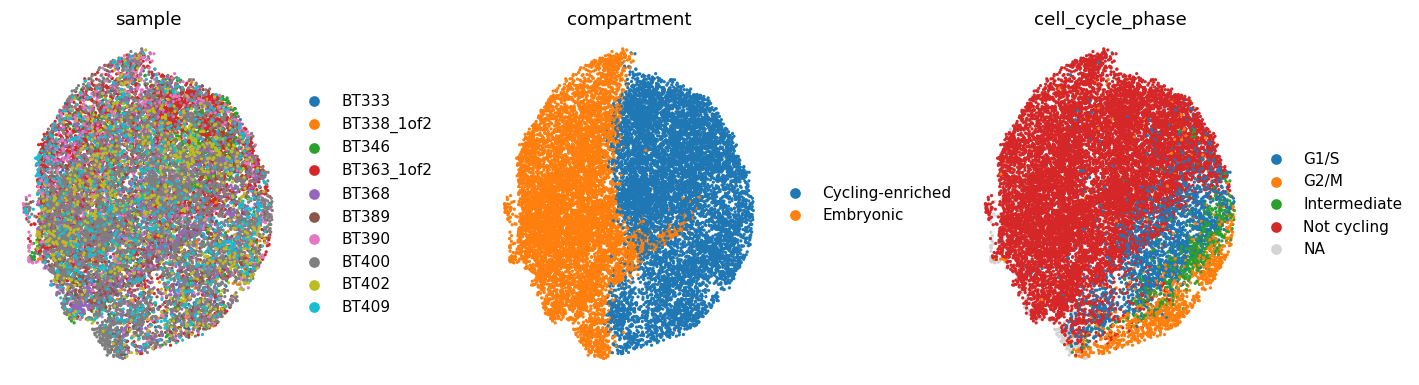

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['sample', 'compartment', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=18, frameon=False, show=False, ax=ax, title=col)
plt.tight_layout(); plt.show()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; '
      f'sample iLISI = {ilisi(adata.obsm["X_pca_harmony"][:,:20], adata.obs["sample"].values):.2f} of {n_samp}.')
print('detached islands removed above -> one connected component retained.')
print('GATE 1: samples intermixed on one continuous 10x manifold -> GO')

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (16804, 24023)


### Deliverable — `samples.pdf`

Single sample-coloured manifold UMAP in the house `(3.5, 1.5)` linear-trajectory aspect; sample
intermixing across the strip is the Gate-1 integration evidence. The manifold's major axis is the
developmental axis (verified in 02), so the panel is oriented to that axis for consistency across
all trajectory panels.

saved samples.pdf | cells: 16804


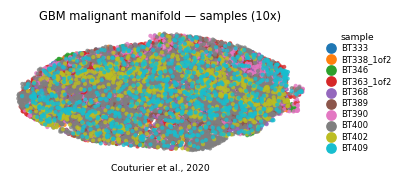

In [11]:
from numpy.linalg import svd
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); u, sv, vt = svd(c, full_matrices=False)
xlp = c @ vt.T                                   # major axis horizontal
plot = adata.copy(); plot.obsm['X_umap'] = xlp
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('GBM malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Couturier et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])